# 05 · Mapa multivariado de 3.072 mudanças de população

> Booster reconstruído com `scale_pos_weight=13.882494684620836`; corte 0,50 apenas para indicadores referenciais. A versão anterior permanece preservada.

**Pergunta:** em centenas de direções conjuntas de mudança, que PSI de perfis, PSI marginal e PSI de pares surgem, e como respondem Brier, AUC ROC, PR-AUC trapezoidal e KS do modelo? Este caderno avalia 256 direções × 12 intensidades = 3.072 cenários, **sem regra de aprovação, reprovação ou parada**.

**Etapas para reutilizar:** (1) congelar o modelo/holdout rotulado; (2) representar X por postos e ausências; (3) gerar direções sem usar Y, em famílias interpretáveis; (4) reponderar linhas reais completas; (5) medir drift realizado e ESS; (6) calcular métricas no conjunto completo e em metades de exploração/confirmação; (7) selecionar extremos só na exploração e verificar na confirmação; (8) fazer bootstrap pareado e inspecionar pares finos. A hipótese é mudança de P(X) dentro do suporte com P(Y|X) estável; não simula desfechos de novos perfis inexistentes.

In [1]:
from pathlib import Path

# Resolve o projeto tanto pelo Jupyter aberto em notebooks/ quanto pelo executor.
_inicio = Path.cwd().resolve()
PROJECT_ROOT = next(
    (p for p in (_inicio, *_inicio.parents)
     if (p / "models" / "manifesto_modelo.json").is_file()),
    None,
)
if PROJECT_ROOT is None:
    raise FileNotFoundError("Não encontrei models/manifesto_modelo.json. Abra o projeto clonado.")
DATA_DIR_PROJECT = PROJECT_ROOT / "data" / "raw"
MODEL_DIR = PROJECT_ROOT / "models"
TABLES_DIR = PROJECT_ROOT / "results" / "tables"
FIGURES_DIR = PROJECT_ROOT / "results" / "figures"
TABLES_DIR.mkdir(parents=True, exist_ok=True)
FIGURES_DIR.mkdir(parents=True, exist_ok=True)
for _nome in ("cs-training.csv", "cs-test.csv"):
    if not (DATA_DIR_PROJECT / _nome).is_file():
        raise FileNotFoundError(
            f"Falta {DATA_DIR_PROJECT / _nome}. Veja README.md, seção Dados."
        )


In [2]:
from pathlib import Path
from itertools import combinations
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import xgboost as xgb
from scipy.stats import qmc
from sklearn.cluster import MiniBatchKMeans
from sklearn.model_selection import train_test_split
from sklearn.metrics import roc_auc_score, average_precision_score, precision_recall_curve, roc_curve, auc as area_curva
from IPython.display import display

SEED = 33
FEATURES = [
    'RevolvingUtilizationOfUnsecuredLines', 'age',
    'NumberOfTime30-59DaysPastDueNotWorse', 'DebtRatio', 'MonthlyIncome',
    'NumberOfOpenCreditLinesAndLoans', 'NumberOfTimes90DaysLate',
    'NumberRealEstateLoansOrLines', 'NumberOfTime60-89DaysPastDueNotWorse',
    'NumberOfDependents'
]
TARGET = 'SeriousDlqin2yrs'
P = DATA_DIR_PROJECT
DATA_DIR = next((d for d in (P, P.parent) if (d / 'cs-training.csv').is_file()), None)
if DATA_DIR is None:
    raise FileNotFoundError('Coloque os CSVs em data/raw/ e execute a partir da raiz do projeto ou de notebooks/.')
OUTPUT_DIR = TABLES_DIR
MODEL_PATH = MODEL_DIR / 'model_class_retreinado.json'
RESULTS_PATH = OUTPUT_DIR / 'resultados_multivariado_populacional.csv'
assert MODEL_PATH.exists(), f'Modelo congelado ausente: {MODEL_PATH}'
CORTE = 0.5
INTENSIDADES = np.array([0.01, 0.02, 0.04, 0.06, 0.09, 0.13, 0.19, 0.28, 0.40, 0.55, 0.75, 1.0])
plt.rcParams.update({'figure.dpi': 110, 'axes.spines.top': False, 'axes.spines.right': False})
print('Modelo:', MODEL_PATH)
print('CSV:', RESULTS_PATH)
print('Todas as intensidades serão executadas; nenhuma regra de parada é aplicada.')

Modelo: .\models\model_class_retreinado.json
CSV: .\results\tables\resultados_multivariado_populacional.csv
Todas as intensidades serão executadas; nenhuma regra de parada é aplicada.


In [3]:
# Verifica que o modelo, o manifesto e a configuração deste estudo coincidem.
import hashlib as _hashlib
import json as _json
_manifesto_versao = _json.loads(
    (MODEL_DIR / "manifesto_modelo.json").read_text(encoding="utf-8")
)
assert abs(_manifesto_versao["params_fornecidos"]["scale_pos_weight"]
           - 13.882494684620836) < 1e-12
assert _manifesto_versao["cutoff"] == 0.5
assert _manifesto_versao["features"] == FEATURES
_arquivo_modelo_versao = MODEL_DIR / "model_class_retreinado.json"
assert _hashlib.sha256(_arquivo_modelo_versao.read_bytes()).hexdigest() == \
       _manifesto_versao["model_sha256"], "Booster e manifesto divergentes."
print("Modelo validado:", _manifesto_versao["variant"])


Modelo validado: metricas_brier_auc_prauc_ks_grade_5a50


## 1. Recuperar exatamente o holdout rotulado e o modelo congelado

O split com semente 33 reproduz as 22.500 linhas de teste do notebook original. Carregamos o Booster já reconstruído, sem reajustar árvores ou escolher limiar com os rótulos de teste. A divisão exploratória/confirmatória ocorre **depois** desse split, só para controlar a busca entre cenários.

In [4]:
df = pd.read_csv(DATA_DIR / 'cs-training.csv').drop(columns='Unnamed: 0')
assert list(df.drop(columns=TARGET).columns) == FEATURES
assert df[TARGET].notna().all()
X = df[FEATURES]
y = df[TARGET].astype(int)
X_train_val, X_test, y_train_val, y_test = train_test_split(
    X, y, test_size=0.15, random_state=SEED
)
X_train, X_val, y_train, y_val = train_test_split(
    X_train_val, y_train_val, test_size=0.1765, random_state=SEED
)
assert len(X_test) == 22500
model_class = xgb.Booster()
model_class.load_model(str(MODEL_PATH))
if model_class.feature_names is not None:
    assert model_class.feature_names == FEATURES
p_test = np.asarray(model_class.predict(
    xgb.DMatrix(X_test, feature_names=FEATURES, enable_categorical=True),
    iteration_range=(0, model_class.num_boosted_rounds())
), dtype=np.float64)
y_array = y_test.to_numpy(dtype=np.int8)
assert np.isfinite(p_test).all() and len(p_test) == 22500
idx_exp, idx_conf = train_test_split(
    np.arange(len(X_test)), test_size=0.5, stratify=y_array, random_state=SEED + 501
)
idx_exp, idx_conf = np.sort(idx_exp), np.sort(idx_conf)
assert len(idx_exp) + len(idx_conf) == 22500 and np.intersect1d(idx_exp, idx_conf).size == 0
print('Treino / validação / holdout:', len(X_train), len(X_val), len(X_test))
print('Exploração / confirmação:', len(idx_exp), len(idx_conf))
print('Eventos exploração / confirmação:', int(y_array[idx_exp].sum()), int(y_array[idx_conf].sum()))
print('Rodadas do modelo:', model_class.num_boosted_rounds())

Treino / validação / holdout: 104996 22504 22500
Exploração / confirmação: 11250 11250
Eventos exploração / confirmação: 750 750
Rodadas do modelo: 103


## 2. Suporte e base de comparação

Reponderar linhas completas nunca cria um valor novo; assim, não há nada a truncar. O mínimo e o máximo de cada variável ficam dentro do suporte **do holdout que recebeu peso positivo**. Como o holdout pode conter valores que já excediam os limites empíricos do treino, conferimos isso explicitamente. Não mudamos esses valores: alterar X e manter Y original tornaria métricas de acerto contrafactuais sem justificativa. O notebook de extrapolação deve tratá-los separadamente como sensibilidade de score.

Para o desenho de cenários, mapeamos cada variável para seu posto empírico em `[-1,1]`; valores ausentes recebem posto central, e a própria ausência entra no agrupamento de perfis. Isso impede que outliers numéricos extremos determinem a intensidade sozinhos.

In [5]:
train_min = X_train.min(skipna=True)
train_max = X_train.max(skipna=True)
outside = X_test.lt(train_min, axis='columns') | X_test.gt(train_max, axis='columns')
range_table = pd.DataFrame({
    'min_treino': train_min,
    'max_treino': train_max,
    'n_holdout_fora_faixa_treino': outside.sum(),
})
display(range_table)
print('Linhas de holdout originalmente fora de pelo menos uma faixa de treino:', int(outside.any(axis=1).sum()))

rank_cols = [X_test[c].rank(method='average', pct=True).fillna(0.5).to_numpy() for c in FEATURES]
Z = np.column_stack(rank_cols) * 2 - 1
missing = X_test[FEATURES].isna().to_numpy(dtype=float)
assert Z.shape == (22500, 10) and np.isfinite(Z).all()

,min_treino,max_treino,n_holdout_fora_faixa_treino
RevolvingUtilizationOfUnsecuredLines,0.0,50708.0,0
age,0.0,109.0,0
NumberOfTime30-59DaysPastDueNotWorse,0.0,98.0,0
DebtRatio,0.0,329664.0,0
MonthlyIncome,0.0,3008750.0,0
NumberOfOpenCreditLinesAndLoans,0.0,58.0,0
NumberOfTimes90DaysLate,0.0,98.0,0
NumberRealEstateLoansOrLines,0.0,54.0,0
NumberOfTime60-89DaysPastDueNotWorse,0.0,98.0,0
NumberOfDependents,0.0,13.0,0


Linhas de holdout originalmente fora de pelo menos uma faixa de treino: 0


## 3. Quatro métricas ponderadas com cache de scores

Os scores não mudam quando apenas a frequência de linhas muda. Ordenamos os scores uma vez por amostra e agregamos empates. Com pesos $w_i\geq0$: Brier é $\sum w_i(y_i-p_i)^2/\sum w_i$; AUC ROC é a área TPR×FPR; PR-AUC trapezoidal é a área precisão×recall calculada por trapézios; KS do modelo é $\max_t(TPR_t-FPR_t)$. Para as três últimas, maior é melhor; para Brier, menor. AP, baseada em degraus, é coluna auxiliar e não se confunde com PR-AUC trapezoidal.

ESS total e por classe $=(\sum w)^2/\sum w^2$ revelam concentração; `recall_05` e `precision_05` são referenciais no corte 0,50. Validamos a implementação vetorizada versus sklearn, inclusive pesos zero. KS do modelo usa Y e scores; PSI e KS de drift usam distribuições de X e não são desempenho.

In [6]:
class MetricCache:
    def __init__(self, yy, score):
        self.yy = np.asarray(yy, dtype=np.int8)
        self.score = np.asarray(score, dtype=np.float64)
        self.order = np.argsort(-self.score, kind='mergesort')
        self.y_sorted = self.yy[self.order]
        self.score_sorted = self.score[self.order]
        self.starts = np.r_[0, np.flatnonzero(np.diff(self.score_sorted) != 0) + 1]
        self.pred = self.score >= CORTE
        self.error2 = (self.yy - self.score) ** 2
        self.pos = self.yy == 1
        self.neg = ~self.pos
        assert self.pos.any() and self.neg.any()

    def evaluate(self, weight):
        w = np.asarray(weight, dtype=np.float64)
        assert len(w) == len(self.yy) and np.isfinite(w).all() and (w >= 0).all()
        ws = w[self.order]
        pos_g = np.add.reduceat(ws * self.y_sorted, self.starts)
        neg_g = np.add.reduceat(ws * (1 - self.y_sorted), self.starts)
        pos_total, neg_total = pos_g.sum(), neg_g.sum()
        assert pos_total > 0 and neg_total > 0, 'AUC/AP exigem peso positivo em ambas as classes.'
        pos_cum = np.cumsum(pos_g)
        all_cum = np.cumsum(pos_g + neg_g)
        neg_below = neg_total - np.cumsum(neg_g)
        auc = np.sum(pos_g * (neg_below + 0.5 * neg_g)) / (pos_total * neg_total)
        precision_by_group = np.divide(pos_cum, all_cum,
                                       out=np.zeros_like(pos_cum), where=all_cum>0)
        ap = np.sum((pos_g / pos_total) * precision_by_group)
        neg_cum = np.cumsum(neg_g)
        recall_by_group = pos_cum / pos_total
        fpr_by_group = neg_cum / neg_total
        ks_modelo = max(0.0, float(np.max(recall_by_group - fpr_by_group)))
        prior_total = np.r_[0.0, all_cum[:-1]]
        prior_precision = np.r_[1.0, precision_by_group[:-1]]
        prior_precision = np.where(prior_total > 0, prior_precision, 1.0)
        prauc_trap = float(np.sum(0.5*(prior_precision+precision_by_group)*pos_g/pos_total))
        tp = w[self.pos & self.pred].sum()
        fp = w[self.neg & self.pred].sum()
        sw = w.sum()
        ess = sw**2 / np.square(w).sum()
        wp, wn = w[self.pos], w[self.neg]
        prevalence = pos_total / sw
        out = {
            'auc': auc, 'prauc_trap': prauc_trap, 'ks_modelo': ks_modelo,
            'ap': ap, 'ap_lift': ap / prevalence,
            'brier': np.dot(w, self.error2) / sw,
            'recall_05': tp / pos_total,
            'precision_05': tp / (tp + fp) if tp + fp else np.nan,
            'fpr_05': fp / neg_total,
            'prevalencia': prevalence,
            'ess': ess, 'ess_ratio': ess / len(w),
            'ess_pos': wp.sum()**2 / np.square(wp).sum(),
            'ess_neg': wn.sum()**2 / np.square(wn).sum(),
        }
        return out

cache_full = MetricCache(y_array, p_test)
cache_exp = MetricCache(y_array[idx_exp], p_test[idx_exp])
cache_conf = MetricCache(y_array[idx_conf], p_test[idx_conf])
baseline = cache_full.evaluate(np.ones(len(y_array)))
baseline_exp = cache_exp.evaluate(np.ones(len(idx_exp)))
baseline_conf = cache_conf.evaluate(np.ones(len(idx_conf)))

def validate_against_sklearn(cache, weight):
    got = cache.evaluate(weight)
    yy, ss = cache.yy, cache.score
    auc_ref = roc_auc_score(yy, ss, sample_weight=weight)
    ap_ref = average_precision_score(yy, ss, sample_weight=weight)
    prec_ref, rec_ref, _ = precision_recall_curve(yy, ss, sample_weight=weight)
    fpr_ref, tpr_ref, _ = roc_curve(yy, ss, sample_weight=weight)
    prauc_ref = area_curva(rec_ref, prec_ref)
    ks_ref = np.max(tpr_ref-fpr_ref)
    brier_ref = np.average((yy - ss)**2, weights=weight)
    np.testing.assert_allclose([got['auc'],got['prauc_trap'],got['ks_modelo'],got['ap'],got['brier']],
                               [auc_ref,prauc_ref,ks_ref,ap_ref,brier_ref], rtol=0, atol=2e-12)
    return np.max(np.abs(np.array([got['auc']-auc_ref,got['prauc_trap']-prauc_ref,got['ks_modelo']-ks_ref,got['ap']-ap_ref,got['brier']-brier_ref])))

rng_check = np.random.default_rng(SEED + 200)
check_weights = np.exp(rng_check.normal(0, 0.9, len(y_array)))
print('Erro máximo vs scikit-learn:', validate_against_sklearn(cache_full, check_weights))
print('Erro no basal:', validate_against_sklearn(cache_full, np.ones(len(y_array))))
check_zero = check_weights.copy()
check_zero[np.argsort(-p_test)[:500]] = 0
check_zero[rng_check.random(len(check_zero)) < 0.2] = 0
print('Erro com pesos zero e grupos iniciais vazios:', validate_against_sklearn(cache_full, check_zero))
display(pd.DataFrame([baseline], index=['holdout completo']).round(5))

Erro máximo vs scikit-learn: 8.881784197001252e-16
Erro no basal: 5.551115123125783e-17
Erro com pesos zero e grupos iniciais vazios: 8.881784197001252e-16


,auc,prauc_trap,ks_modelo,ap,ap_lift,brier,recall_05,precision_05,fpr_05,prevalencia,ess,ess_ratio,ess_pos,ess_neg
holdout completo,0.86684,0.39599,0.58771,0.39639,5.94578,0.14404,0.794,0.21525,0.20676,0.06667,22500.0,1.0,1500.0,21000.0


## 4. Gerar 256 direções sem escolher perfis a partir de Y

Cada família usa 64 pontos Sobol embaralhados em 32 dimensões (`random_base2(m=6)`), com semente fixa; avaliamos cada direção nas mesmas 12 intensidades. A grade é mais densa junto do basal para resolver melhor a resposta inicial. O efeito sobre a população é w_i(t) ∝ exp[t·g(X_i)], com 0 < t ≤ 1. A normalização dos pesos não altera as métricas, mas torna a escala e o ESS comparáveis. O driver g depende **só de X**, nunca do rótulo ou score.

* **Postos esparsos:** 2–5 variáveis selecionadas por Sobol, cada uma orientada para alto ou baixo.
* **Caudas conjuntas:** peso elevado somente quando várias variáveis caminham juntas para as caudas escolhidas; usamos o mínimo dos postos orientados.
* **Interações:** produto de postos de dois atributos para favorecer concordância ou discordância observadas.
* **Mistura de perfis:** 16 grupos `MiniBatchKMeans` estimados sem Y; Sobol define fatores diferentes para cada grupo.

Em todos os casos os valores da linha inteira permanecem intactos. A reponderação pode alterar as **correlações agregadas** da população; ela preserva a coerência de cada perfil observado, não promete uma matriz de correlação idêntica.

In [7]:
cluster_input = np.column_stack([Z, 0.5 * missing]).astype(np.float32)
clusterer = MiniBatchKMeans(n_clusters=16, random_state=SEED + 800,
                            batch_size=2048, n_init=5, max_iter=150)
cluster = clusterer.fit_predict(cluster_input)
cluster_counts = np.bincount(cluster, minlength=16)
assert (cluster_counts > 0).all()
print('Tamanhos dos 16 grupos X-only:', cluster_counts.tolist())

PAIRS = list(combinations(range(10), 2))
families = ['postos_esparsos', 'caudas_conjuntas', 'interacao_par', 'mistura_clusters']
rays = []
for fidx, family in enumerate(families):
    sobol = qmc.Sobol(d=32, scramble=True, seed=SEED + 1000 + fidx)
    U = sobol.random_base2(m=6)
    for ray_id, u in enumerate(U):
        info = {'familia': family, 'raio': ray_id}
        if family in ('postos_esparsos', 'caudas_conjuntas'):
            k = 2 + min(3, int(4*u[0]))
            if family == 'caudas_conjuntas':
                k = min(k, 4)
            selected = np.argsort(u[2:12])[:k]
            signs = np.where(u[12:22][selected] < 0.5, -1.0, 1.0)
            oriented = Z[:, selected] * signs
            if family == 'postos_esparsos':
                driver = 6.0 * oriented.mean(axis=1)
            else:
                driver = 6.0 * oriented.min(axis=1)
            info['variaveis'] = ' | '.join(('+' if s > 0 else '-') + FEATURES[j]
                                           for j, s in zip(selected, signs))
            info['n_variaveis'] = k
            info['par'] = ''
        elif family == 'interacao_par':
            pair = PAIRS[min(44, int(45*u[0]))]
            sign = 1.0 if u[1] >= 0.5 else -1.0
            driver = 10.0 * sign * Z[:, pair[0]] * Z[:, pair[1]]
            info['variaveis'] = f'{FEATURES[pair[0]]} | {FEATURES[pair[1]]}'
            info['n_variaveis'] = 2
            info['par'] = 'concordante' if sign > 0 else 'discordante'
        else:
            group_signal = 4.5 * (2*u[2:18] - 1)
            driver = group_signal[cluster]
            info['variaveis'] = 'todos: grupos X-only'
            info['n_variaveis'] = 10
            info['par'] = ''
        info['driver'] = np.asarray(driver, dtype=np.float64)
        assert np.std(info['driver']) > 1e-8
        rays.append(info)

assert len(rays) == 256
used = set()
for r in rays:
    if r['familia'] != 'mistura_clusters':
        used.update(j for j, name in enumerate(FEATURES) if name in r['variaveis'])
assert len(used) == 10
print('Direções:', len(rays), '| cenários:', len(rays)*len(INTENSIDADES),
      '| variáveis cobertas:', len(used))
display(pd.DataFrame([{k:v for k,v in r.items() if k != 'driver'} for r in rays])
        .groupby('familia').agg(raios=('raio','count'), minimo_k=('n_variaveis','min'),
                               maximo_k=('n_variaveis','max')))

Tamanhos dos 16 grupos X-only: [1452, 1018, 778, 1046, 1367, 2230, 1650, 944, 1339, 1179, 1952, 1815, 1677, 1300, 1709, 1044]
Direções: 256 | cenários: 3072 | variáveis cobertas: 10


,raios,minimo_k,maximo_k
familia,,,
caudas_conjuntas,64,2,4
interacao_par,64,2,2
mistura_clusters,64,10,10
postos_esparsos,64,2,5


## 5. Distâncias de drift e guardrails

O PSI conjunto compara as participações dos 16 grupos de X antes e depois da reponderação. Para o PSI marginal e bivariado, os **cortes são fixados usando apenas o treino do modelo** e aplicados sem recalibração ao holdout. A distribuição de referência do PSI de cada cenário é o **holdout sem pesos**; a distribuição de comparação é o mesmo holdout reponderado. Assim, PSI zero na intensidade zero é esperado.

O binning separa valores negativos (anomalia de domínio), zero, positivos e ausentes; infinitos têm uma categoria própria de entrada inválida. Nas variáveis de contagem, 1, 2 e 3 formam categorias distintas quando presentes no treino, e a cauda positiva recebe cortes adicionais derivados somente do treino. Nas demais variáveis, os positivos usam quantis do treino. O máximo observado no treino também é um corte: valores futuros acima dele ocupam uma faixa separada. Essa regra impede que muitos zeros façam os atrasos de 90 dias e de 60–89 dias colapsarem em um só bin. O PSI do par usa o produto cartesiano desses mesmos bins congelados.

O PSI mede **mudança da composição**, não perda de desempenho. As quatro métricas são calculadas separadamente com baseline próprio para holdout completo, exploração e confirmação. Todas as intensidades são mantidas, incluindo as de ESS pequeno; interprete estas últimas com cautela. Bins discretos raros podem produzir PSI instável, especialmente com células vazias. Os cortes e tratamento de ausências precisam ser versionados para monitoramento futuro.

In [8]:
# O tipo de variável é parte explícita da configuração que deve ser congelada em produção.
COUNT_FEATURES = {
    'NumberOfTime30-59DaysPastDueNotWorse',
    'NumberOfOpenCreditLinesAndLoans',
    'NumberOfTimes90DaysLate',
    'NumberRealEstateLoansOrLines',
    'NumberOfTime60-89DaysPastDueNotWorse',
    'NumberOfDependents',
}

def cortes_psi_treino(train_col):
    """Cortes determinísticos definidos somente pela amostra de treino."""
    ref = np.asarray(train_col, dtype=float)
    finite = ref[np.isfinite(ref)]
    if not len(finite):
        raise ValueError(f'{train_col.name}: referência sem valores finitos')
    if (finite < 0).any():
        raise ValueError(f'{train_col.name}: adapte o binning para referência com negativos')
    positive = finite[finite > 0]
    if not len(positive):
        return np.array([], dtype=float)
    if train_col.name in COUNT_FEATURES:
        if not np.all(np.isclose(positive, np.rint(positive))):
            raise ValueError(f'{train_col.name}: variável de contagem com frações')
        # Categorias 1, 2 e 3; os quantis adicionais resumem a cauda >3.
        small = np.array([v for v in (1., 2., 3.) if np.any(positive == v)])
        tail = np.unique(positive[positive > 3])
        if len(tail):
            quantiles = np.quantile(positive[positive > 3], [.5, .9])
            tail_cuts = tail[np.searchsorted(tail, quantiles, side='left').clip(max=len(tail)-1)]
        else:
            tail_cuts = np.array([], dtype=float)
        cuts = np.r_[small, tail_cuts, positive.max()]
    else:
        cuts = np.r_[np.quantile(positive, np.linspace(.1, .9, 9)), positive.max()]
    return np.unique(cuts.astype(float))

def codificar_psi(values, cuts):
    """0=negativo; 1=zero; 2..=positivos; penúltimo=infinito; último=NaN."""
    v = np.asarray(values, dtype=float)
    n_bins = len(cuts) + 5
    codes = np.full(len(v), n_bins-1, dtype=np.int16)  # NaN
    codes[np.isinf(v)] = n_bins-2
    finite = np.isfinite(v)
    codes[finite & (v < 0)] = 0
    codes[finite & (v == 0)] = 1
    pos = finite & (v > 0)
    codes[pos] = 2 + np.searchsorted(cuts, v[pos], side='left')
    assert ((codes >= 0) & (codes < n_bins)).all()
    return codes, n_bins

psi_cuts = {f: cortes_psi_treino(X_train[f]) for f in FEATURES}
psi_specs = [codificar_psi(X_test[f], psi_cuts[f]) for f in FEATURES]

def psi_hist(codes, n_bins, weights):
    w = np.asarray(weights, dtype=float)
    assert len(codes) == len(w) and np.isfinite(w).all() and (w >= 0).all() and w.sum() > 0
    p = np.bincount(codes, minlength=n_bins).astype(float)
    q = np.bincount(codes, weights=w, minlength=n_bins).astype(float)
    eps = 1e-12
    p = (p+eps)/(p.sum()+eps*n_bins)
    q = (q+eps)/(q.sum()+eps*n_bins)
    return float(np.sum((q-p)*np.log(q/p)))

# Testes de regressão: constantes, faltantes e atrasos esparsos não podem colapsar.
for probe in [pd.Series([0., 0., 0.]), pd.Series([5., 5., 5.]),
              pd.Series([np.nan, 5., 5.])]:
    cuts = cortes_psi_treino(probe)
    ids, bins = codificar_psi(probe, cuts)
    assert abs(psi_hist(ids, bins, np.ones(len(probe)))) < 1e-12
zero_cuts = cortes_psi_treino(pd.Series([0., 0., 0.]))
probe_ids, probe_bins = codificar_psi(np.array([-1., 0., 1., np.inf, np.nan]), zero_cuts)
assert probe_bins == 5 and len(np.unique(probe_ids)) == 5
constant_cuts = cortes_psi_treino(pd.Series([5., 5., 5.]))
constant_ids, _ = codificar_psi(np.array([5., 6.]), constant_cuts)
assert constant_ids[0] != constant_ids[1], 'Faixa acima do máximo de treino não foi preservada'
for f in ['NumberOfTimes90DaysLate', 'NumberOfTime60-89DaysPastDueNotWorse']:
    ids, bins = psi_specs[FEATURES.index(f)]
    shock = np.where(X_test[f].to_numpy(dtype=float) > 0, 2., 1.)
    assert (ids == 1).any() and (ids >= 2).any()
    assert psi_hist(ids, bins, shock) > .001, f'PSI perdeu zero versus positivo: {f}'
    age_ids, age_bins = psi_specs[FEATURES.index('age')]
    pair_codes = ids.astype(np.int32) * age_bins + age_ids.astype(np.int32)
    assert psi_hist(pair_codes, bins*age_bins, shock) > .001, f'PSI par colapsou: {f}'
assert all(abs(psi_hist(ids, bins, np.ones(len(ids)))) < 1e-12 for ids, bins in psi_specs)
print('Binning validado: zero, positivos, faltantes e PSI bivariado preservados.')
display(pd.DataFrame({
    'variavel': FEATURES,
    'n_bins': [n for _, n in psi_specs],
    'cortes_positivos_treino': [psi_cuts[f].tolist() for f in FEATURES],
    'fração_zero_holdout': [(X_test[f] == 0).mean() for f in FEATURES],
    'fração_ausente_holdout': [X_test[f].isna().mean() for f in FEATURES],
}))

def weight_for(driver, intensity):
    logw = intensity * driver
    w = np.exp(logw - logw.max())
    return w / w.mean()

assert psi_hist(cluster, 16, np.ones(len(cluster))) < 1e-15

Binning validado: zero, positivos, faltantes e PSI bivariado preservados.


,variavel,n_bins,cortes_positivos_treino,fração_zero_holdout,fração_ausente_holdout
0,RevolvingUtilizationOfUnsecuredLines,15,"[0.012811516, 0.031634853, 0.06053420050000002...",0.073644,0.000000
1,age,15,"[33.0, 39.0, 44.0, 48.0, 52.0, 56.0, 61.0, 65....",0.000000,0.000000
2,NumberOfTime30-59DaysPastDueNotWorse,10,"[1.0, 2.0, 3.0, 5.0, 98.0]",0.836667,0.000000
3,DebtRatio,15,"[0.05985158790000001, 0.1519871778, 0.22798754...",0.029556,0.000000
4,MonthlyIncome,15,"[2200.0, 3053.0, 3900.0, 4603.0, 5442.0, 6400....",0.011956,0.196889
5,NumberOfOpenCreditLinesAndLoans,11,"[1.0, 2.0, 3.0, 9.0, 16.0, 58.0]",0.013378,0.000000
6,NumberOfTimes90DaysLate,10,"[1.0, 2.0, 3.0, 6.0, 98.0]",0.943244,0.000000
7,NumberRealEstateLoansOrLines,11,"[1.0, 2.0, 3.0, 4.0, 7.0, 54.0]",0.376267,0.000000
8,NumberOfTime60-89DaysPastDueNotWorse,9,"[1.0, 2.0, 3.0, 98.0]",0.948133,0.000000
9,NumberOfDependents,11,"[1.0, 2.0, 3.0, 4.0, 5.0, 13.0]",0.579289,0.027200


## 6. Executar os 3.072 cenários

Cada direção e cada intensidade recebe métricas no holdout completo e em duas metades estratificadas, com **baselines próprios**. Registramos deltas Brier, AUC, PR-AUC trapezoidal e KS, PSI conjunto dos 16 grupos, PSI marginal das dez entradas, ESS e métricas referenciais em 0,50. A coluna `cenario_id` identifica o mesmo mecanismo nas duas metades; nenhuma linha é omitida por desempenho ou ESS.

In [9]:
started = time.perf_counter()
rows = []
CAMPOS_CENTRAIS = ['brier','auc','prauc_trap','ks_modelo']
for ray_n, ray in enumerate(rays):
    for intensity in INTENSIDADES:
        w = weight_for(ray['driver'], intensity)
        mf = cache_full.evaluate(w)
        me = cache_exp.evaluate(w[idx_exp])
        mc = cache_conf.evaluate(w[idx_conf])
        psi_cols = [psi_hist(codes, n_bins, w) for codes, n_bins in psi_specs]
        row = {
            'cenario_id': len(rows), 'familia': ray['familia'], 'raio': ray['raio'],
            'intensidade': float(intensity), 'variaveis': ray['variaveis'],
            'n_variaveis': ray['n_variaveis'], 'par': ray['par'],
            'psi_conjunto_16_clusters': psi_hist(cluster, 16, w),
            'psi_marginal_max': max(psi_cols),
            'psi_marginal_soma': sum(psi_cols),
            **mf,
        }
        for campo in CAMPOS_CENTRAIS:
            row[f'delta_{campo}'] = mf[campo]-baseline[campo]
        for sufixo, m, b in [('exploracao',me,baseline_exp),('confirmacao',mc,baseline_conf)]:
            for campo in CAMPOS_CENTRAIS:
                row[f'{campo}_{sufixo}'] = m[campo]
                row[f'delta_{campo}_{sufixo}'] = m[campo]-b[campo]
            for campo in ['ap','recall_05','precision_05','prevalencia','ess_ratio','ess_pos','ess_neg']:
                row[f'{campo}_{sufixo}'] = m[campo]
        row.update({f'psi_{c}':float(v) for c,v in zip(FEATURES,psi_cols)})
        rows.append(row)
    if (ray_n+1) % 64 == 0:
        print(f'{ray_n+1}/256 direções; {len(rows)} cenários; {time.perf_counter()-started:.1f}s')
resultados = pd.DataFrame(rows)
assert len(resultados) == 3072 and resultados['cenario_id'].is_unique
assert resultados.groupby('familia').size().eq(768).all()
RESULTS_PATH.parent.mkdir(parents=True, exist_ok=True)
resultados.to_csv(RESULTS_PATH,index=False,encoding='utf-8-sig')
print('Tempo total:',round(time.perf_counter()-started,1),'s | CSV:',RESULTS_PATH)
display(resultados.groupby('familia').agg(
    cenarios=('cenario_id','count'),
    mediana_psi_conjunto=('psi_conjunto_16_clusters','median'),
    max_psi_conjunto=('psi_conjunto_16_clusters','max'),
    menor_ess_ratio=('ess_ratio','min'),
    delta_ks_min=('delta_ks_modelo','min'),
    delta_prauc_min=('delta_prauc_trap','min'),
    delta_brier_max=('delta_brier','max')).round(5))

64/256 direções; 768 cenários; 2.9s


128/256 direções; 1536 cenários; 5.9s


192/256 direções; 2304 cenários; 9.0s


256/256 direções; 3072 cenários; 12.1s
Tempo total: 12.2 s | CSV: .\results\tables\resultados_multivariado_populacional.csv


,cenarios,mediana_psi_conjunto,max_psi_conjunto,menor_ess_ratio,delta_ks_min,delta_prauc_min,delta_brier_max
familia,,,,,,,
caudas_conjuntas,768,0.04150,4.11941,0.00536,-0.34416,-0.31034,0.30257
interacao_par,768,0.01878,4.47454,0.00272,-0.43502,-0.19789,0.33293
mistura_clusters,768,0.13749,5.41128,0.08700,-0.16433,-0.16685,0.14280
postos_esparsos,768,0.03140,2.90805,0.04387,-0.24084,-0.20519,0.24315


## 7. Selecionar extremos na exploração e confirmar

Em cada família, restringimos a busca à **maior intensidade pré-definida** e escolhemos a direção com menor delta de KS na metade exploratória. Na metade confirmatória, avaliamos **a mesma direção/intensidade**, sem nova escolha. Isto ilustra replicação de um extremo selecionado; não é limite global nem regra de parada. A seleção por Y na exploração causa otimismo esperado, que a confirmação ajuda a revelar. Também exibimos as quatro métricas para evitar avaliar somente KS.

In [10]:
forte = resultados[np.isclose(resultados.intensidade,max(INTENSIDADES))]
selected = (forte.sort_values('delta_ks_modelo_exploracao')
            .groupby('familia',sort=False).head(1).sort_values('familia').reset_index(drop=True))
colunas = ['familia','raio','variaveis','intensidade','psi_conjunto_16_clusters','ess_ratio',
           'delta_brier_exploracao','delta_brier_confirmacao',
           'delta_auc_exploracao','delta_auc_confirmacao',
           'delta_prauc_trap_exploracao','delta_prauc_trap_confirmacao',
           'delta_ks_modelo_exploracao','delta_ks_modelo_confirmacao']
display(selected[colunas].round(5))

,familia,raio,variaveis,intensidade,psi_conjunto_16_clusters,ess_ratio,delta_brier_exploracao,delta_brier_confirmacao,delta_auc_exploracao,delta_auc_confirmacao,delta_prauc_trap_exploracao,delta_prauc_trap_confirmacao,delta_ks_modelo_exploracao,delta_ks_modelo_confirmacao
0,caudas_conjuntas,22,-age | +NumberOfTime60-89DaysPastDueNotWorse |...,1.0,2.91403,0.00916,0.29524,0.22831,-0.21729,-0.15310,0.11365,0.18763,-0.29046,-0.23751
1,interacao_par,7,age | NumberOfTimes90DaysLate,1.0,3.66027,0.00865,0.33892,0.28632,-0.28603,-0.22709,0.13922,0.20096,-0.42515,-0.35116
2,mistura_clusters,49,todos: grupos X-only,1.0,5.41128,0.12094,-0.00318,-0.00554,-0.13940,-0.03798,-0.16594,-0.13793,-0.23638,-0.04131
3,postos_esparsos,8,+NumberOfTimes90DaysLate | +NumberOfTime30-59D...,1.0,1.86857,0.04387,0.27054,0.21651,-0.14356,-0.13451,0.24268,0.27089,-0.21538,-0.23916


## 8. Envelope exploratório e verificação

Dividimos o PSI conjunto em até dez faixas quantílicas. Para cada faixa e **cada uma das quatro métricas**, escolhemos na exploração o maior Brier ou o menor AUC/PR-AUC/KS. O ponto da confirmação pertence ao mesmo cenário escolhido e usa seu próprio baseline. Assim vemos se extremos observados persistem sem reutilizar Y na seleção. O envelope é apenas o pior **dentro dos mecanismos testados** e pode mudar com a grade. Não fornece limite matemático universal.

,metrica,faixa,n_cenarios,psi_mediano_faixa,cenario_id,familia,exploracao,confirmacao,ess_ratio
0,Brier,0,308,0.00015,2031,interacao_par,0.00378,0.00287,0.99300
1,Brier,1,307,0.00076,1985,interacao_par,0.00898,0.00616,0.95535
2,Brier,2,307,0.00333,1986,interacao_par,0.01729,0.01239,0.86471
3,Brier,3,307,0.01075,1727,interacao_par,0.03876,0.03763,0.72647
4,Brier,4,307,0.02756,1677,interacao_par,0.04584,0.07055,0.04728
5,Brier,5,307,0.07611,1916,interacao_par,0.09206,0.06676,0.21829
6,Brier,6,307,0.19285,2109,interacao_par,0.13340,0.10551,0.18525
7,Brier,7,307,0.43453,2110,interacao_par,0.20818,0.16239,0.08951
8,Brier,8,307,0.91732,1918,interacao_par,0.30010,0.18889,0.01907
9,Brier,9,308,2.22693,1607,interacao_par,0.39440,0.21771,0.00480


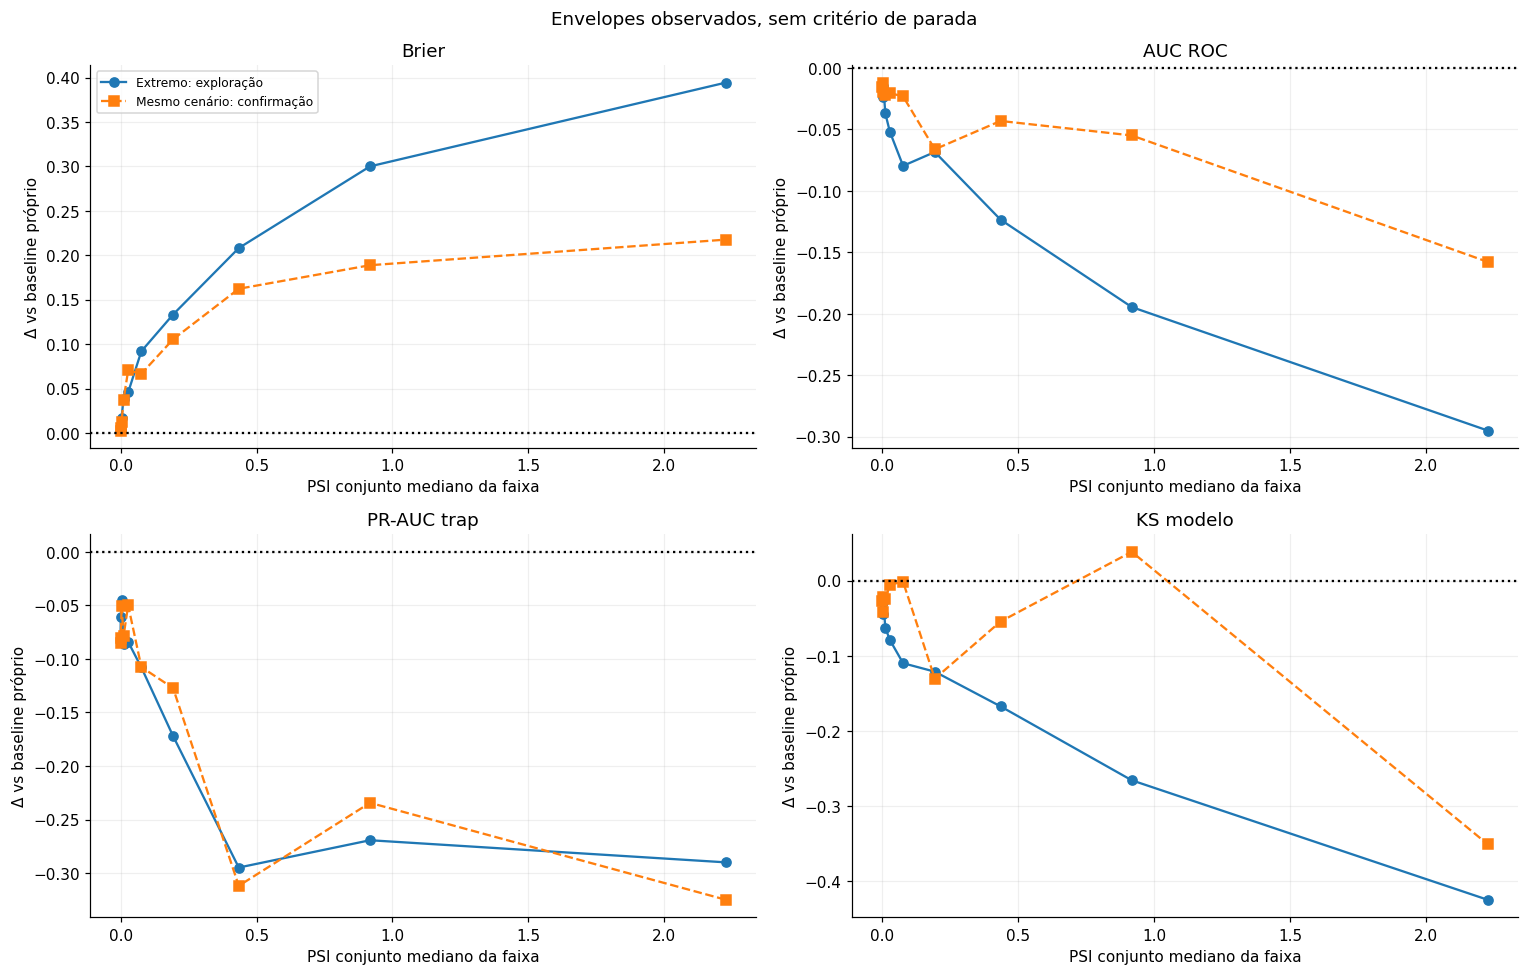

In [11]:
resultados['faixa_psi'] = pd.qcut(resultados['psi_conjunto_16_clusters'],
                                 q=10, labels=False, duplicates='drop')
metric_specs = [
    ('Brier','delta_brier_exploracao','delta_brier_confirmacao','max'),
    ('AUC ROC','delta_auc_exploracao','delta_auc_confirmacao','min'),
    ('PR-AUC trap','delta_prauc_trap_exploracao','delta_prauc_trap_confirmacao','min'),
    ('KS modelo','delta_ks_modelo_exploracao','delta_ks_modelo_confirmacao','min'),
]
envelope_rows = []
for metric_name, exp_col, conf_col, direction in metric_specs:
    for band, sub in resultados.groupby('faixa_psi'):
        chosen = sub.loc[sub[exp_col].idxmin() if direction=='min' else sub[exp_col].idxmax()]
        envelope_rows.append({'metrica':metric_name,'faixa':int(band),'n_cenarios':len(sub),
            'psi_mediano_faixa':sub['psi_conjunto_16_clusters'].median(),
            'cenario_id':int(chosen['cenario_id']),'familia':chosen['familia'],
            'exploracao':chosen[exp_col],'confirmacao':chosen[conf_col],
            'ess_ratio':chosen['ess_ratio']})
envelope = pd.DataFrame(envelope_rows)
display(envelope.round(5))
fig, axes = plt.subplots(2,2,figsize=(14,9))
for ax,(name,_,_,_) in zip(axes.flat,metric_specs):
    sub = envelope[envelope['metrica']==name]
    ax.plot(sub['psi_mediano_faixa'],sub['exploracao'],'o-',label='Extremo: exploração')
    ax.plot(sub['psi_mediano_faixa'],sub['confirmacao'],'s--',label='Mesmo cenário: confirmação')
    ax.axhline(0,color='black',ls=':')
    ax.set(title=name,xlabel='PSI conjunto mediano da faixa',ylabel='Δ vs baseline próprio')
    ax.grid(alpha=.2)
axes[0,0].legend(fontsize=8)
fig.suptitle('Envelopes observados, sem critério de parada')
fig.tight_layout(); plt.show()

## 9. Drift conjunto, desempenho e efeitos marginais

O PSI conjunto de 16 clusters é uma projeção resumida de X. Pontos com PSI parecido podem apresentar efeitos opostos. O primeiro painel mostra deltas de Brier, AUC, PR-AUC e KS; o mapa mostra PSI marginal mediano por família. ESS fica no CSV. A cor da família indica o mecanismo gerador, sem classificação de aprovação.

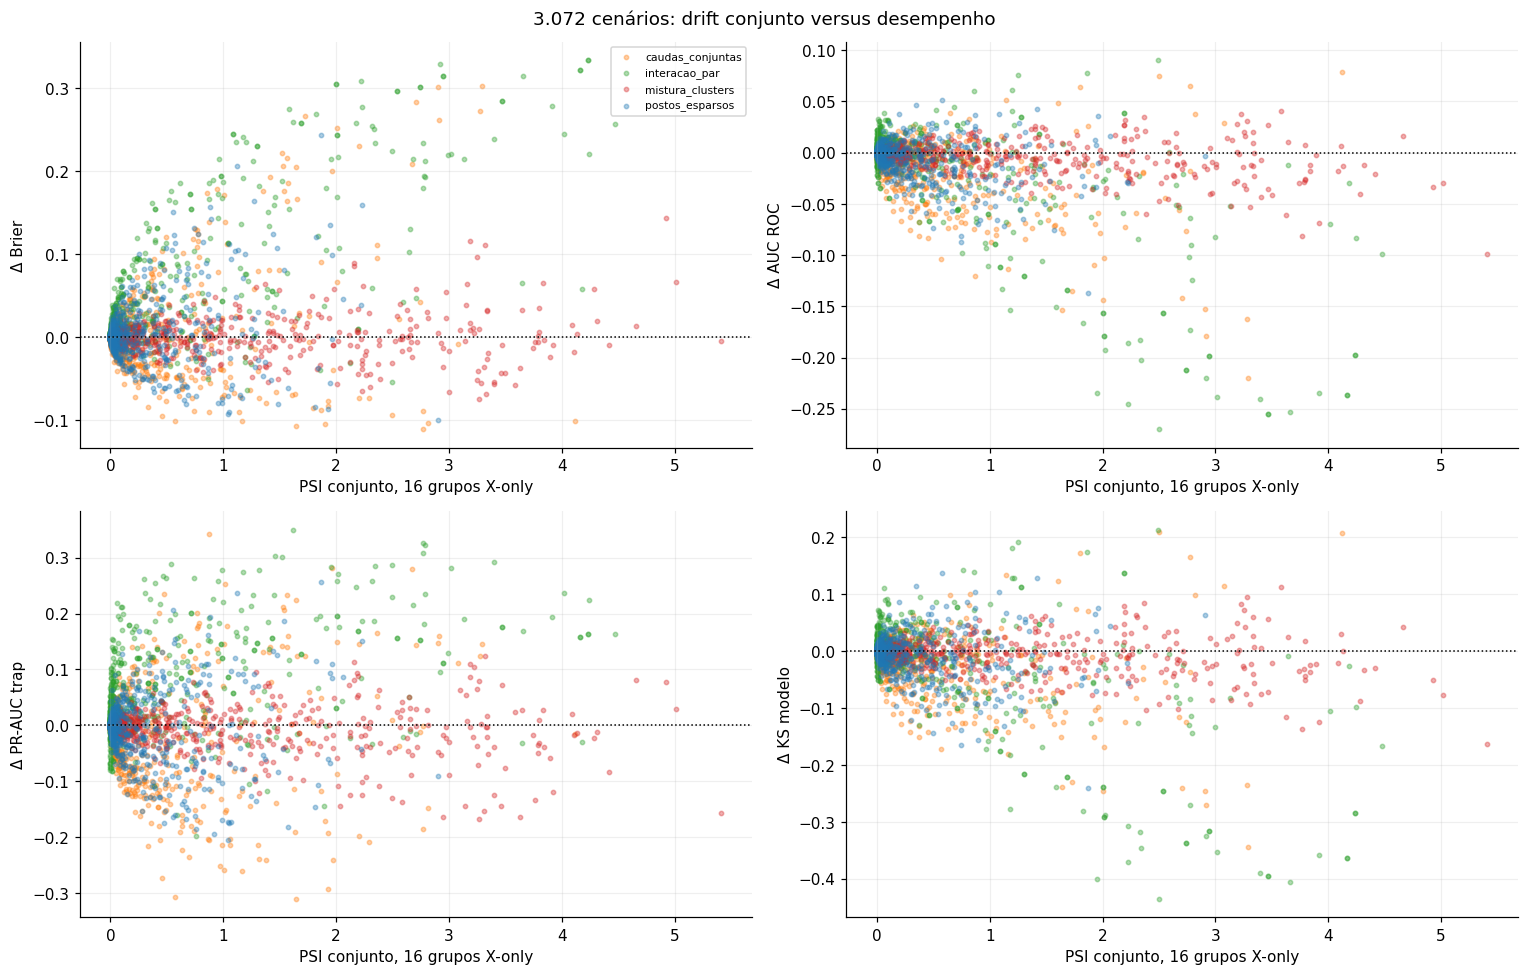

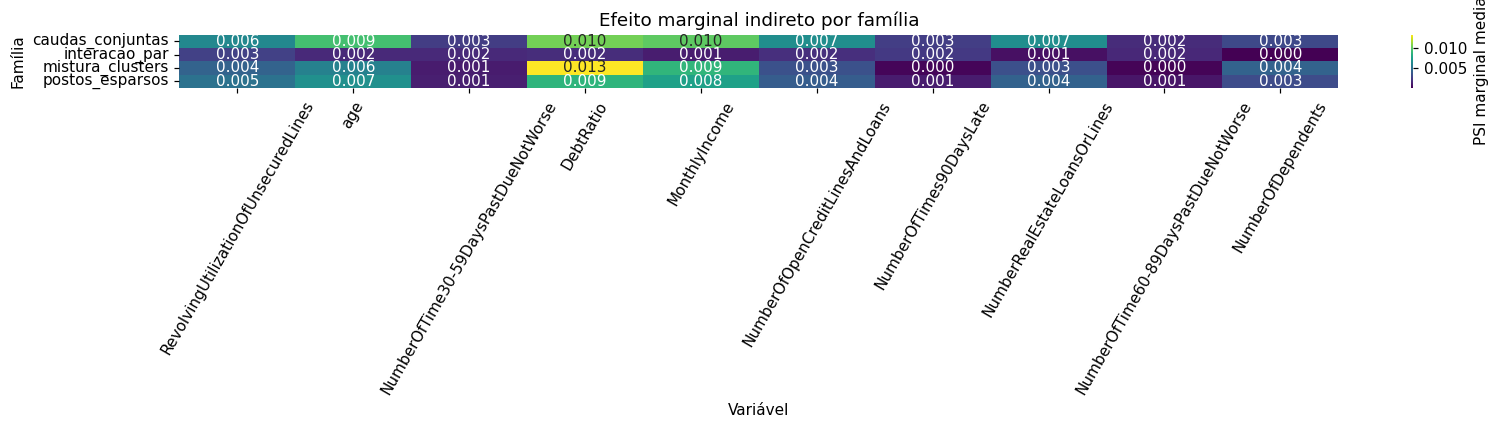

In [12]:
fig, axes = plt.subplots(2,2,figsize=(14,9))
plot_items = [('delta_brier','Δ Brier'),('delta_auc','Δ AUC ROC'),
              ('delta_prauc_trap','Δ PR-AUC trap'),('delta_ks_modelo','Δ KS modelo')]
palette = dict(zip(families,sns.color_palette('tab10',4)))
for ax,(col,label) in zip(axes.flat,plot_items):
    for fam, sub in resultados.groupby('familia'):
        ax.scatter(sub['psi_conjunto_16_clusters'],sub[col],s=8,alpha=.36,
                   c=[palette[fam]],label=fam)
    ax.axhline(0,color='black',ls=':',lw=1)
    ax.set(xlabel='PSI conjunto, 16 grupos X-only',ylabel=label)
    ax.grid(alpha=.2)
axes[0,0].legend(fontsize=7)
fig.suptitle('3.072 cenários: drift conjunto versus desempenho')
fig.tight_layout(); plt.show()
psi_columns = [f'psi_{c}' for c in FEATURES]
spillover = resultados.groupby('familia')[psi_columns].median()
spillover.columns = FEATURES
fig, ax = plt.subplots(figsize=(15,4))
sns.heatmap(spillover,cmap='viridis',annot=True,fmt='.3f',
            cbar_kws={'label':'PSI marginal mediano'},ax=ax)
ax.set(title='Efeito marginal indireto por família',xlabel='Variável',ylabel='Família')
ax.tick_params(axis='x',labelrotation=60)
plt.tight_layout(); plt.show()

## 10. Bootstrap pareado dos extremos escolhidos

Para cada família, fazemos 120 reamostragens **estratificadas por Y na metade confirmatória** do cenário selecionado pela exploração. Em cada réplica, baseline e cenário usam os mesmos índices; o intervalo percentil 95% descreve o delta. Este procedimento condiciona ao mecanismo selecionado e mantém a prevalência de classes da metade confirmatória. Não cobre seleção de famílias, treino do modelo nem futuros regimes. A análise continua descritiva, sem teste de aprovação.

In [13]:
rng_boot = np.random.default_rng(SEED + 2030)
N_BOOT = 120
boot_rows = []
for sel in selected.itertuples():
    ray = next(r for r in rays if r['familia']==sel.familia and r['raio']==sel.raio)
    w_full = weight_for(ray['driver'], sel.intensidade)
    w_conf = w_full[idx_conf]
    yy_conf, pp_conf = y_array[idx_conf], p_test[idx_conf]
    ipos, ineg = np.flatnonzero(yy_conf==1), np.flatnonzero(yy_conf==0)
    samples = {campo:[] for campo in CAMPOS_CENTRAIS}
    for _ in range(N_BOOT):
        boot_idx = np.r_[rng_boot.choice(ipos,len(ipos),replace=True),
                         rng_boot.choice(ineg,len(ineg),replace=True)]
        cb = MetricCache(yy_conf[boot_idx],pp_conf[boot_idx])
        b0 = cb.evaluate(np.ones(len(boot_idx)))
        bs = cb.evaluate(w_conf[boot_idx])
        for campo in CAMPOS_CENTRAIS:
            samples[campo].append(bs[campo]-b0[campo])
    row = {'familia':sel.familia,'raio':sel.raio,
           'intensidade':sel.intensidade,'psi_conjunto':sel.psi_conjunto_16_clusters}
    for campo,values in samples.items():
        row[f'delta_{campo}_ic95_inf'],row[f'delta_{campo}_ic95_sup'] = np.quantile(values,[.025,.975])
    boot_rows.append(row)
incerteza = pd.DataFrame(boot_rows)
display(incerteza.round(5))

,familia,raio,intensidade,psi_conjunto,delta_brier_ic95_inf,delta_brier_ic95_sup,delta_auc_ic95_inf,delta_auc_ic95_sup,delta_prauc_trap_ic95_inf,delta_prauc_trap_ic95_sup,delta_ks_modelo_ic95_inf,delta_ks_modelo_ic95_sup
0,caudas_conjuntas,22,1.0,2.91403,0.14541,0.29364,-0.24254,-0.06038,0.05480,0.34397,-0.32705,-0.05396
1,interacao_par,7,1.0,3.66027,0.19551,0.35118,-0.31803,-0.11314,0.08531,0.35670,-0.44260,-0.13793
2,mistura_clusters,49,1.0,5.41128,-0.01335,0.00161,-0.08015,0.00601,-0.19815,-0.04472,-0.12124,0.03938
3,postos_esparsos,8,1.0,1.86857,0.18836,0.24585,-0.17492,-0.07784,0.20452,0.33469,-0.30930,-0.12600


## 11. Diagnóstico conjunto fino para interações entre pares

Os 16 grupos agregam perfis distintos. Para cada um dos 768 cenários de interação, calculamos um segundo PSI na tabela bidimensional de bins das duas variáveis efetivamente usadas pelo mecanismo. Os bins são definidos no treino e incluem faltantes. Isso ajuda a detectar uma mudança de dependência que o agrupamento grosso esconda. O valor é diagnóstico e não um limite universal. O CSV final recebe uma coluna para essa medida; os outros mecanismos ficam sem esse PSI específico.


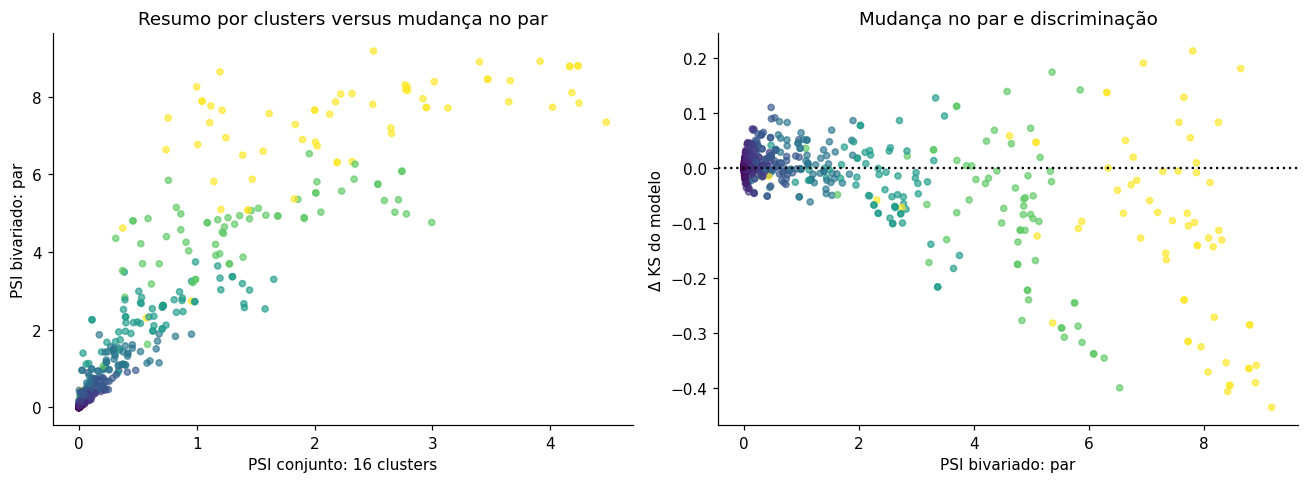

Cenário selecionado na exploração: PSI 16 clusters = 3.660268 ; PSI bivariado do par = 8.413946 ; Δ KS modelo confirmação = -0.35116
CSV atualizado: .\results\tables\resultados_multivariado_populacional.csv


In [14]:
resultados['psi_par_interacao'] = np.nan
pair_bins = {}
for ray in rays:
    if ray['familia'] != 'interacao_par':
        continue
    names = ray['variaveis'].split(' | ')
    pair = tuple(FEATURES.index(name) for name in names)
    if pair not in pair_bins:
        (a, na), (b, nb) = psi_specs[pair[0]], psi_specs[pair[1]]
        pair_bins[pair] = (a.astype(np.int32) * nb + b.astype(np.int32), na * nb)
    codes, n_bins = pair_bins[pair]
    idx = resultados.index[(resultados['familia']=='interacao_par') &
                           (resultados['raio']==ray['raio'])]
    for k in idx:
        w = weight_for(ray['driver'], float(resultados.at[k, 'intensidade']))
        resultados.at[k, 'psi_par_interacao'] = psi_hist(codes, n_bins, w)
assert resultados.loc[resultados.familia=='interacao_par', 'psi_par_interacao'].notna().all()
assert resultados.loc[resultados.familia!='interacao_par', 'psi_par_interacao'].isna().all()
resultados.to_csv(RESULTS_PATH, index=False, encoding='utf-8-sig')

inter = resultados[resultados.familia=='interacao_par']
fig, axes = plt.subplots(1,2,figsize=(12,4.5))
axes[0].scatter(inter.psi_conjunto_16_clusters,inter.psi_par_interacao,
                c=inter.intensidade,cmap='viridis',s=16,alpha=.65)
axes[0].set(xlabel='PSI conjunto: 16 clusters',ylabel='PSI bivariado: par',
            title='Resumo por clusters versus mudança no par')
axes[1].scatter(inter.psi_par_interacao,inter.delta_ks_modelo,
                c=inter.intensidade,cmap='viridis',s=16,alpha=.65)
axes[1].axhline(0,color='black',ls=':')
axes[1].set(xlabel='PSI bivariado: par',ylabel='Δ KS do modelo',
            title='Mudança no par e discriminação')
fig.tight_layout(); plt.show()
sel_pair = selected[selected.familia=='interacao_par'].iloc[0]
linha_pair = inter[(inter.raio==sel_pair.raio) &
                   np.isclose(inter.intensidade,sel_pair.intensidade)].iloc[0]
print('Cenário selecionado na exploração: PSI 16 clusters =',
      round(linha_pair.psi_conjunto_16_clusters,6),
      '; PSI bivariado do par =',round(linha_pair.psi_par_interacao,6),
      '; Δ KS modelo confirmação =',round(linha_pair.delta_ks_modelo_confirmacao,6))
print('CSV atualizado:',RESULTS_PATH)

## 11. Síntese e limites de inferência

O conjunto de resultados é uma **superfície de resposta condicionada** às quatro famílias de mecanismos, 256 direções, 12 intensidades e ao holdout disponível. PSI igual não garante impacto igual; direção, prevalência e ESS importam. O extremo escolhido na exploração pode enfraquecer na confirmação; por isso relatamos ambos e o bootstrap. Não há uma tolerância única pronta para produção sem custo de negócio, janela temporal rotulada, política de decisão e critério de precisão acordados.

A reponderação conserva perfis individuais reais, mas pode alterar correlações agregadas. Não cria valores além do suporte, erros de medição nem mudança de P(Y|X). Para isso, consulte os outros cadernos da suíte. `cs-test.csv` sem rótulo não permite medir Brier/AUC/PR-AUC/KS de crédito.

**Referências de mecanismo:** [Sugiyama et al., 2007](https://www.jmlr.org/papers/v8/sugiyama07a.html) para covariate shift; [SciPy Sobol](https://docs.scipy.org/doc/scipy/reference/generated/scipy.stats.qmc.Sobol.html) para geração de direções; [scikit-learn PR-AUC/AP](https://scikit-learn.org/stable/modules/generated/sklearn.metrics.precision_recall_curve.html) para definições de curva; [Namkoong e Duchi, 2016](https://papers.nips.cc/paper_files/paper/2016/hash/4588e674d3f0faf985047d4c3f13ed0d-Abstract.html) para robustez distribucional. Estas fontes fundamentam conceitos, não os valores numéricos obtidos neste caso.

In [15]:
print('Baseline completo: Brier={:.5f}, AUC={:.5f}, PR-AUC trap={:.5f}, KS modelo={:.5f}'.format(
    baseline['brier'],baseline['auc'],baseline['prauc_trap'],baseline['ks_modelo']))
print(f'Cenários executados: {len(resultados)} em {len(rays)} direções; nenhum descartado por limite.')
print('Extremos selecionados por menor Δ KS na exploração, na maior intensidade:')
display(selected[colunas].round(5))
print('Arquivo detalhado:',RESULTS_PATH)

Baseline completo: Brier=0.14404, AUC=0.86684, PR-AUC trap=0.39599, KS modelo=0.58771
Cenários executados: 3072 em 256 direções; nenhum descartado por limite.
Extremos selecionados por menor Δ KS na exploração, na maior intensidade:


,familia,raio,variaveis,intensidade,psi_conjunto_16_clusters,ess_ratio,delta_brier_exploracao,delta_brier_confirmacao,delta_auc_exploracao,delta_auc_confirmacao,delta_prauc_trap_exploracao,delta_prauc_trap_confirmacao,delta_ks_modelo_exploracao,delta_ks_modelo_confirmacao
0,caudas_conjuntas,22,-age | +NumberOfTime60-89DaysPastDueNotWorse |...,1.0,2.91403,0.00916,0.29524,0.22831,-0.21729,-0.15310,0.11365,0.18763,-0.29046,-0.23751
1,interacao_par,7,age | NumberOfTimes90DaysLate,1.0,3.66027,0.00865,0.33892,0.28632,-0.28603,-0.22709,0.13922,0.20096,-0.42515,-0.35116
2,mistura_clusters,49,todos: grupos X-only,1.0,5.41128,0.12094,-0.00318,-0.00554,-0.13940,-0.03798,-0.16594,-0.13793,-0.23638,-0.04131
3,postos_esparsos,8,+NumberOfTimes90DaysLate | +NumberOfTime30-59D...,1.0,1.86857,0.04387,0.27054,0.21651,-0.14356,-0.13451,0.24268,0.27089,-0.21538,-0.23916


Arquivo detalhado: .\results\tables\resultados_multivariado_populacional.csv
